# Session 5: CNN on MNIST and YOLOv8

This notebook contains structured tasks for building a CNN on MNIST and experimenting with Ultralytics YOLOv8 (pretrained inference and a short training example).

**Instructions:**
- Complete all tasks directly in this notebook.
- Keep your code clear and well-commented.
- Use `%matplotlib inline` for visualizations.
- If you need to install packages (e.g., `ultralytics`), use `%pip` in a cell.
- When using external datasets, do NOT upload them to GitHub.

### ***DO NOT UPLOAD LARGE DATASETS OR MODEL WEIGHTS TO GITHUB***
<hr>

## Task 1: Convolutional Neural Network on MNIST — Build, Train, Evaluate, Visualize
Train a simple CNN on the MNIST handwritten digits dataset. After training, generate predictions on the test set, compare them to ground truth labels, and visualize a few results.

**Why this matters:**
- MNIST is a classic entry point for image classification and CNNs.
- You will practice the full workflow: data loading, model definition, training, evaluation, and visualization.

**Steps:**
- Load MNIST with appropriate transforms (normalize).
- Define a small CNN (Conv → ReLU → Pool → FC).
- Train for a few epochs (2–3 for demo).
- Evaluate on the test set and compute accuracy.
- Visualize several test images with predicted and true labels.

**Hint:** Use `torchvision.datasets.MNIST`, `DataLoader`, `nn.Conv2d`, `nn.ReLU`, `nn.MaxPool2d`, and `nn.CrossEntropyLoss`.

In [1]:
import sys
print(sys.executable)

c:\Users\Prof. Ahmed ElShafee\Desktop\skyXperts\.venv\Scripts\python.exe


In [2]:
%pip install torch torchvision

  Using cached torch-2.14.1-cp314-cp314-win_amd64.whl.metadata (38 kB)
  Using cached torchvision-0.29.1-cp314-cp314-win_amd64.whl.metadata (5.7 kB)
Using cached torch-2.14.1-cp314-cp314-win_amd64.whl (124.1 MB)
Using cached torchvision-0.29.1-cp314-cp314-win_amd64.whl (1.4 MB)

   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 [torch]
   ---------------------------------------- 0/2 

In [6]:
import torch
import torchvision
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

torch.manual_seed(42)
np.random.seed(42)
#help make results reproducible

device= torch.device("cuda" if torch.cuda.is_available() else "cpu") #uses CUDA when a compatible GPU is available otherwise, it uses the CPU.

print("PyTorch version:", torch.__version__) 
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)
print("Device:", device)


Matplotlib is building the font cache; this may take a moment.


PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
NumPy version: 2.5.4
Device: cpu


In [7]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

#convert images to tensors and normalize them
transform= transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

#loading the training dataset
train_dataset= datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

#loading the testing dataset
test_dataset= datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader= DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader= DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)
#the data loaders are used to load the training and testing datasets in batches, which is useful for training neural networks.
#we shuffle the training data to ensure that the model does not learn any order or pattern in the data, which can lead to overfitting.

print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))
print("Training batches:", len(train_loader))
print("Testing batches:", len(test_loader))


Training images: 60000
Testing images: 10000
Training batches: 938
Testing batches: 157


In [8]:
import torch.nn as nn
import torch.nn.functional as F

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()

        #convolutional layer: 1 input channel, 16 output channels
        self.conv1= nn.Conv2d(1, 16, kernel_size=3, padding=1)

        #Max pooling reduces image dimensions from 28x28 to 14x14
        self.pool= nn.MaxPool2d(kernel_size=2, stride=2)

        #Fully connected layer
        self.fc1= nn.Linear(16 * 14 * 14, 128)

        #Output layer: 10 classes (digits 0-9)
        self.fc2= nn.Linear(128, 10)

    def forward(self, x):
        #Convolution followed by ReLU and max pooling
        x= self.pool(F.relu(self.conv1(x)))
        #Flatten feature maps into a 1D vector
        x= torch.flatten(x, start_dim=1)
        #Fully connected layer followed by ReLU
        x= F.relu(self.fc1(x))
        #Return logits for 10 classes
        x= self.fc2(x)
        return x

#Create the model and move it to the selected device
model= SimpleCNN().to(device)

print(model)


SimpleCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
)


In [9]:
criterion = nn.CrossEntropyLoss() #measures the difference between the model's predictions and the correct digit labels
optimizer = torch.optim.Adam(model.parameters(), lr=0.001) #updates the model weights 


num_epochs= 3

for epoch in range(num_epochs):
    model.train()

    running_loss= 0
    correct= 0
    total= 0

    for images, labels in train_loader:
        images= images.to(device)
        labels= labels.to(device)

        optimizer.zero_grad() #clears gradients from the previous batch.

        outputs= model(images)

        loss= criterion(outputs, labels)

        loss.backward()

        #update model parameters
        optimizer.step()
       
        running_loss+= loss.item()

        #Calculate training accuracy
        _, predicted= torch.max(outputs, 1)
        total+= labels.size(0)
        correct+= (predicted == labels).sum().item()

    epoch_loss=running_loss/len(train_loader)
    epoch_accuracy=100*correct/total

    print(
        f"Epoch [{epoch + 1}/{num_epochs}], "
        f"Loss: {epoch_loss:.4f}, "
        f"Accuracy: {epoch_accuracy:.2f}%"
    )


Epoch [1/3], Loss: 0.2648, Accuracy: 92.27%
Epoch [2/3], Loss: 0.0841, Accuracy: 97.45%
Epoch [3/3], Loss: 0.0582, Accuracy: 98.21%


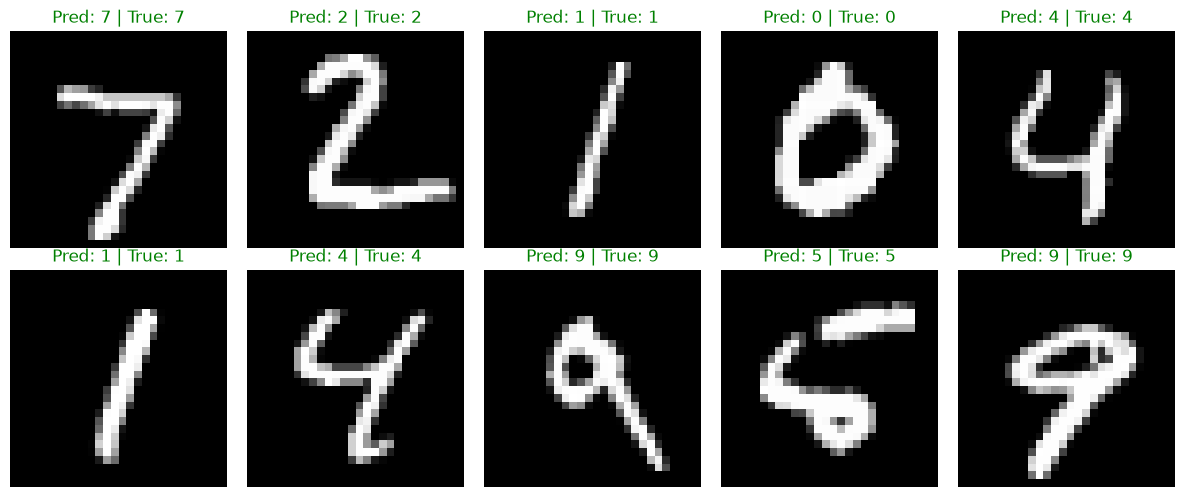

In [10]:
import torch
import matplotlib.pyplot as plt
#got one batch from the test DataLoader
images, labels = next(iter(test_loader))
#run the model in evaluation mode
model.eval()


images= images.to(device)

with torch.no_grad():
    outputs= model(images)
    _, predicted = torch.max(outputs, 1)

 
images= images.cpu()
labels= labels.cpu()
predicted= predicted.cpu()
#moved the data to CPU for visualization

plt.figure(figsize=(12, 5))

for i in range(10):#plot the first 10 images in the batch
    plt.subplot(2, 5, i + 1)

    img= images[i].squeeze()*0.5+0.5 #unnormalize the image for visualization

    plt.imshow(img, cmap="gray")
    plt.title(
        f"Pred: {predicted[i].item()} | True: {labels[i].item()}",
        color="green" if predicted[i] == labels[i] else "red"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


## Task 2: YOLOv8 Pretrained Predictions (No Training)
Use a pretrained YOLOv8 model to run inference on any image of your choice and visualize detections.

**Why this matters:**
- Demonstrates transfer learning and using pretrained models for object detection.
- Learn how to quickly test a detector on real images.

**Steps:**
- Install `ultralytics` if not available.
- Load a YOLOv8 model (e.g., `yolov8n.pt`).
- Run predictions on an image path.
- Visualize the detections (boxes, labels, confidences).

**Hint:** Use `from ultralytics import YOLO`, `YOLO('yolov8n.pt')`, and `model.predict(source=...)`.

In [11]:
%pip install ultralytics

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   -------------- ------------------------- 0.5/1.4 MB 1.7 MB/s eta 0:00:01
   ------------------------------------ --- 1.3/1.4 MB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 2.0 MB/s  0:00:00
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
   ---------------------------------------- 0.0/876.6 kB ? eta -:--:--
   ----------------------- ---------------- 524.3/876.6 kB 2.9 MB/s eta 0:00:01
   ---------------------------------------- 876.6/876.6 kB 2.7 MB/s  0:00:00
   ---------------------------------------- 0.0/54.2 MB ? eta -:--:--
   ---------------------------------------- 0.5/54.2 MB 3.0 MB/s eta 0:00:18
    --------------------------------------- 1.0/54.2 MB 3.0 MB/s eta 0:00:18
   - -------------------------------

In [12]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2 as cv 

#load the pretrained YOLOv8 nano model
model = YOLO('yolov8n.pt') #faster and lightweight version 
#The model was pretrained on the COCO dataset, which includes common objects such as people, cars, dogs, and chairs.

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Prof. Ahmed ElShafee\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [14]:
results= model.predict(source='parrot.png', conf=0.25) #running object detection on the image 'parrot.jpg' with a confidence threshold of 0.25

#first prediction 
result= results[0]


image 1/1 c:\Users\Prof. Ahmed ElShafee\Desktop\skyXperts\parrot.png: 480x640 5 birds, 272.8ms
Speed: 27.3ms preprocess, 272.8ms inference, 2.9ms postprocess per image at shape (1, 3, 480, 640)


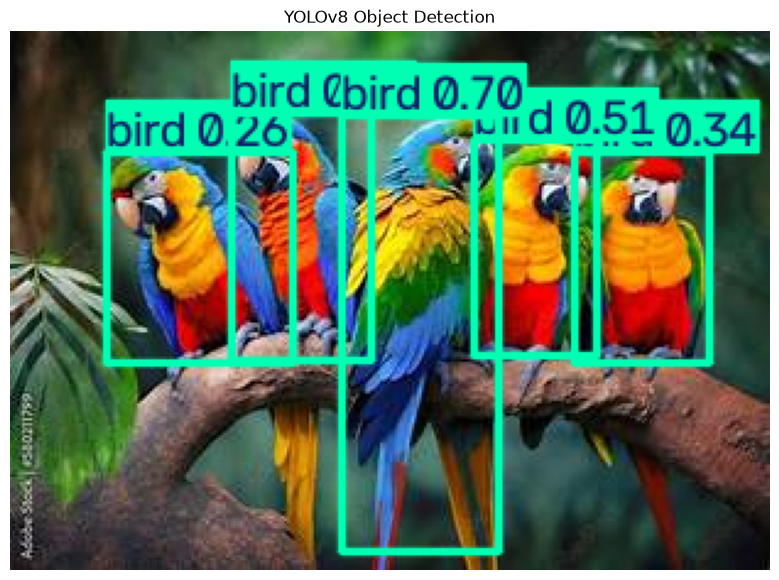

Object: bird, Confidence: 0.70
Object: bird, Confidence: 0.51
Object: bird, Confidence: 0.46
Object: bird, Confidence: 0.34
Object: bird, Confidence: 0.26


In [17]:
annotated_image= result.plot() #get the image with bounding box drawnn
annotated_image= cv.cvtColor(annotated_image, cv.COLOR_BGR2RGB)

plt.figure(figsize=(10, 7))
plt.imshow(annotated_image)
plt.axis('off')
plt.title('YOLOv8 Object Detection')
plt.show()

for box in result.boxes:
    class_id= int(box.cls[0])
    confidence= float(box.conf[0])

    print(
        f"Object: {model.names[class_id]}, "
        f"Confidence: {confidence:.2f}"
    )

## Task 3: YOLOv8 Training Example (Small Demo)
Choose any small dataset (e.g., from Roboflow or Kaggle) and train a YOLOv8 model for a few epochs (e.g., 3) as a demonstration. Then run predictions with the trained model.

**Why this matters:**
- Understand the end-to-end YOLO training pipeline.
- See how dataset configuration (classes, paths) connects to training code.

**Steps:**
- Prepare your dataset directory and a `data.yaml` describing train/val paths and class names.
- Train a small model (e.g., `yolov8n.pt`) for ~3 epochs.
- Run predictions on a few sample images.
- Reflect: Are the predictions what you expected? Why or why not?

**Notes:**
- Do NOT upload datasets to GitHub. Keep them locally or use a data hosting service.
- Training for 3 epochs is just for demonstration; try longer training later.
- If you can't use GPU, small images and fewer epochs help.
- If you can't use GPU, you can train your models on Kaggle or Google Colab in the future for free access to GPUs on their servers

Ultralytics 8.4.176  Python-3.14.7 torch-2.14.1+cpu CPU (Intel Core i7-7500U 2.70GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=coco128.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=3, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=320, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8_demo-2, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto,

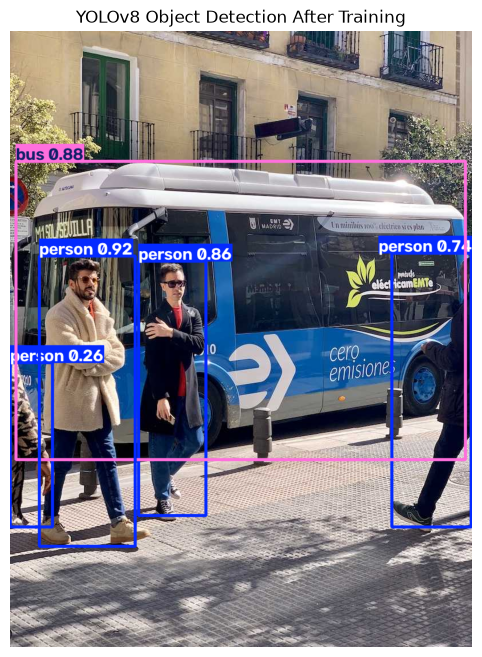

Object: person, Confidence: 0.92
Object: bus, Confidence: 0.88
Object: person, Confidence: 0.86
Object: person, Confidence: 0.74
Object: person, Confidence: 0.26


In [19]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
from pathlib import Path

# first i loaded pretrained YOLOv8 nano model
# The model already has learned weights, so we will fine-tune it.
model= YOLO('yolov8n.pt')

#COCO128 is a small dataset provided by Ultralytics.
#It contains images, labels, train/validation paths, and class names.
data_yaml= 'coco128.yaml'

#YOLO downloads the dataset automatically if it is not available.
#imgsz=320 reduces computation; batch=16 controls images per batch.
train_results= model.train(
    data=data_yaml,
    epochs=3,
    imgsz=320,
    batch=16,
    name='yolov8_demo',
    plots=True
)

#loading the best weights saved during training is important for making predictions with the fine-tuned model
best_weights= Path(model.trainer.save_dir) / 'weights' / 'best.pt'
print("Best model weights:", best_weights)

trained_model= YOLO(str(best_weights))


predictions=trained_model.predict(
    source='bus.jpg',
    conf=0.25,
    save=True
)

annotated_image= predictions[0].plot() #to display the image with bounding boxes, labels, and confidence scores
annotated_image= cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB) #converting the image from BGR to RGB format for proper display with matplotlib

plt.figure(figsize=(12, 8))
plt.imshow(annotated_image)
plt.title('YOLOv8 Object Detection After Training')
plt.axis('off')
plt.show()

for box in predictions[0].boxes:
    class_id= int(box.cls[0])
    confidence= float(box.conf[0])

    print(
        f"Object: {trained_model.names[class_id]}, "
        f"Confidence: {confidence:.2f}"
    )


### Reflection
- Are the predictions what you expected?
- If performance is weak, why? (data size/quality, epochs, augmentations, etc.)
- What would you adjust for a more serious training run?
- What other arguments can you use for the training function.

The model detected objects in the image and displayed their bounding boxes, labels, and confidence scores. The results were generally reasonable


I would train for more epochs, use a larger and more diverse dataset and evaluate the model using validation metrics such as precision, recall.


- epochs: number of complete passes through the training dataset.
- imgsz: input image size.
- batch: number of images processed per batch.
- device: selects the CPU or GPU.
- lr0: initial learning rate.
- optimizer: optimization algorithm, such as SGD or AdamW.

These arguments can be adjusted to improve training efficiency and model performance.